In [1]:

import pandas as pd

# Load a sample sentiment dataset
url = "https://raw.githubusercontent.com/dD2405/Twitter_Sentiment_Analysis/master/train.csv"

df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (31962, 3)


,id,label,tweet
0,1,0,@user when a father is dysfunctional and is s...
1,2,0,@user @user thanks for #lyft credit i can't us...
2,3,0,bihday your majesty
3,4,0,#model i love u take with u all the time in ...
4,5,0,factsguide: society now #motivation


In [2]:

# Check dataset information
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nLabel Distribution:")
print(df['label'].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31962 entries, 0 to 31961
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      31962 non-null  int64 
 1   label   31962 non-null  int64 
 2   tweet   31962 non-null  object
dtypes: int64(2), object(1)
memory usage: 749.2+ KB

Missing Values:
id       0
label    0
tweet    0
dtype: int64

Duplicate Rows:
0

Label Distribution:
label
0    29720
1     2242
Name: count, dtype: int64


In [3]:

import re

def clean_tweet(text):
    text = text.lower()  # Convert to lowercase
    text = re.sub(r'http\S+|www\S+', '', text)  # Remove URLs
    text = re.sub(r'@\w+', '', text)  # Remove mentions
    text = re.sub(r'#', '', text)  # Remove hashtag symbol
    text = re.sub(r'[^a-z\s]', ' ', text)  # Keep letters and spaces
    text = re.sub(r'\s+', ' ', text).strip()  # Remove extra spaces
    return text

# Create a cleaned text column
df['clean_tweet'] = df['tweet'].apply(clean_tweet)

# Compare original and cleaned tweets
df[['tweet', 'clean_tweet']].head()


,tweet,clean_tweet
0,@user when a father is dysfunctional and is s...,when a father is dysfunctional and is so selfi...
1,@user @user thanks for #lyft credit i can't us...,thanks for lyft credit i can t use cause they ...
2,bihday your majesty,bihday your majesty
3,#model i love u take with u all the time in ...,model i love u take with u all the time in ur
4,factsguide: society now #motivation,factsguide society now motivation


In [4]:

from sklearn.model_selection import train_test_split

# Input text and target labels
X = df['clean_tweet']
y = df['label']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 25569
Testing samples: 6393


In [5]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create a text classification pipeline
model = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=10000,
        stop_words='english'
    )),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


Model Accuracy: 93.35%

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.94      0.96      5945
           1       0.52      0.78      0.62       448

    accuracy                           0.93      6393
   macro avg       0.75      0.86      0.79      6393
weighted avg       0.95      0.93      0.94      6393



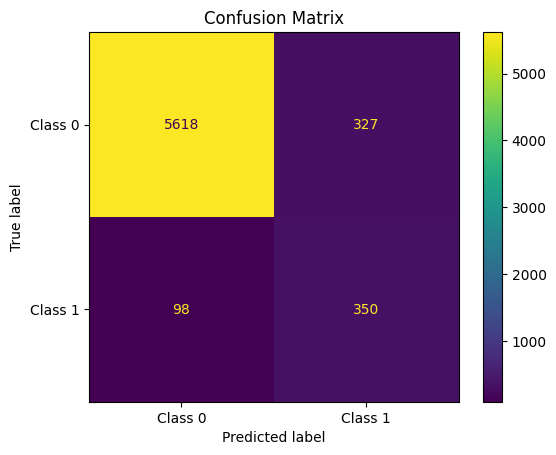

In [6]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict on test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2%}")

# Print precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Class 0', 'Class 1']
)

display.plot()
plt.title("Confusion Matrix")
plt.show()


In [7]:

# Test the model with sample tweets

sample_tweets = [
    "I love this beautiful day and everyone is so kind",
    "I hate those people and they should be treated badly",
    "Having a great time with my friends today!"
]

predictions = model.predict(sample_tweets)

for tweet, prediction in zip(sample_tweets, predictions):
    result = (
        "Racist/Sexist class (1)"
        if prediction == 1
        else "Non-racist/Non-sexist class (0)"
    )
    print("Tweet:", tweet)
    print("Prediction:", result)
    print("-" * 50)


Tweet: I love this beautiful day and everyone is so kind
Prediction: Non-racist/Non-sexist class (0)
--------------------------------------------------
Tweet: I hate those people and they should be treated badly
Prediction: Racist/Sexist class (1)
--------------------------------------------------
Tweet: Having a great time with my friends today!
Prediction: Non-racist/Non-sexist class (0)
--------------------------------------------------


## Conclusion

In this project, a Twitter text classification model was developed using Natural Language Processing (NLP) techniques and Machine Learning.

The dataset was explored and cleaned, and the tweets were preprocessed by converting text to lowercase and removing URLs, mentions, hashtags, special characters, and extra spaces.

TF-IDF was used to convert text into numerical features, and Logistic Regression was used to classify tweets into two categories: non-racist/non-sexist and racist/sexist.

The model achieved **93.35% accuracy** on the test dataset. The classification report showed an F1-score of **0.96 for Class 0** and **0.62 for Class 1**. Sample predictions also demonstrated that the model could classify example tweets.

Overall, this project provided practical experience in text preprocessing, NLP, model training, evaluation, and text classification. Further improvements could focus on reducing false positives and improving the model's performance on Class 1.